In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_excel("2005.xlsx")
df = df[df["x4"] > 0]
df = df[~df["regions"].isin(["Московская область", "Город Москва столица Российской Федерации город федерального значения", "Республика Саха (Якутия)"])].set_index('regions')
df.shape

(71, 4)

In [3]:
df_with_clusters = df.copy()

In [4]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)

for i in df.columns:
    df[i] = df_scaled[:, 0] 

df.head()

,x1,x2,x3,x4
regions,,,,
Алтайский край,-0.833573,-0.833573,-0.833573,-0.833573
Амурская область,-2.019004,-2.019004,-2.019004,-2.019004
Архангельская область,-1.745080,-1.745080,-1.745080,-1.745080
Астраханская область,0.493543,0.493543,0.493543,0.493543
Белгородская область,1.263364,1.263364,1.263364,1.263364


In [5]:
df_with_clusters = df.copy()

In [6]:
agg_cluster = AgglomerativeClustering(n_clusters=5, linkage='ward')
df_with_clusters["clusters"] = agg_cluster.fit_predict(df)

In [7]:
df_with_clusters.groupby(by = ["clusters"]).count() 

,x1,x2,x3,x4
clusters,,,,
0,16,16,16,16
1,10,10,10,10
2,14,14,14,14
3,21,21,21,21
4,10,10,10,10


In [8]:
df_with_clusters[df_with_clusters['clusters'] == 4]

,x1,x2,x3,x4,clusters
regions,,,,,
Астраханская область,0.493543,0.493543,0.493543,0.493543,4
Калужская область,0.710793,0.710793,0.710793,0.710793,4
Омская область,0.706070,0.706070,0.706070,0.706070,4
Пензенская область,0.616336,0.616336,0.616336,0.616336,4
Республика Адыгея (Адыгея),0.706070,0.706070,0.706070,0.706070,4
Республика Татарстан (Татарстан),0.517157,0.517157,0.517157,0.517157,4
Свердловская область,0.427423,0.427423,0.427423,0.427423,4
Ставропольский край,0.644673,0.644673,0.644673,0.644673,4
Тюменская область,0.446314,0.446314,0.446314,0.446314,4


In [9]:
df_with_clusters.reset_index().shape

(71, 6)

In [10]:
df_with_clusters[df_with_clusters.clusters == 0]

,x1,x2,x3,x4,clusters
regions,,,,,
Алтайский край,-0.833573,-0.833573,-0.833573,-0.833573,0
Вологодская область,-1.074438,-1.074438,-1.074438,-1.074438,0
Карачаево-Черкесская Республика,-0.488807,-0.488807,-0.488807,-0.488807,0
Красноярский край,-1.069715,-1.069715,-1.069715,-1.069715,0
Новгородская область,-0.729671,-0.729671,-0.729671,-0.729671,0
Пермский край,-1.098052,-1.098052,-1.098052,-1.098052,0
Приморский край,-1.031932,-1.031932,-1.031932,-1.031932,0
Псковская область,-1.069715,-1.069715,-1.069715,-1.069715,0
Республика Башкортостан,-1.145280,-1.145280,-1.145280,-1.145280,0


<Axes: >

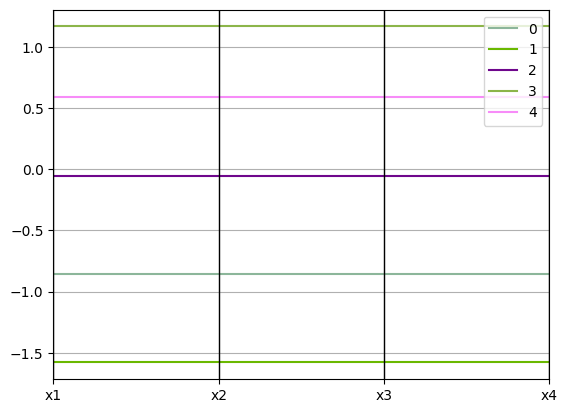

In [11]:
df_with_means = df_with_clusters.groupby(by = ["clusters"]).mean().reset_index()
pd.plotting.parallel_coordinates(df_with_means, "clusters")

{'icoord': [[5.0, 5.0, 15.0, 15.0],
  [35.0, 35.0, 45.0, 45.0],
  [25.0, 25.0, 40.0, 40.0],
  [65.0, 65.0, 75.0, 75.0],
  [55.0, 55.0, 70.0, 70.0],
  [32.5, 32.5, 62.5, 62.5],
  [10.0, 10.0, 47.5, 47.5],
  [95.0, 95.0, 105.0, 105.0],
  [85.0, 85.0, 100.0, 100.0],
  [125.0, 125.0, 135.0, 135.0],
  [115.0, 115.0, 130.0, 130.0],
  [92.5, 92.5, 122.5, 122.5],
  [28.75, 28.75, 107.5, 107.5],
  [155.0, 155.0, 165.0, 165.0],
  [145.0, 145.0, 160.0, 160.0],
  [175.0, 175.0, 185.0, 185.0],
  [195.0, 195.0, 205.0, 205.0],
  [180.0, 180.0, 200.0, 200.0],
  [152.5, 152.5, 190.0, 190.0],
  [235.0, 235.0, 245.0, 245.0],
  [225.0, 225.0, 240.0, 240.0],
  [265.0, 265.0, 275.0, 275.0],
  [255.0, 255.0, 270.0, 270.0],
  [295.0, 295.0, 305.0, 305.0],
  [285.0, 285.0, 300.0, 300.0],
  [262.5, 262.5, 292.5, 292.5],
  [232.5, 232.5, 277.5, 277.5],
  [215.0, 215.0, 255.0, 255.0],
  [171.25, 171.25, 235.0, 235.0],
  [68.125, 68.125, 203.125, 203.125],
  [325.0, 325.0, 335.0, 335.0],
  [345.0, 345.0, 355.0, 35

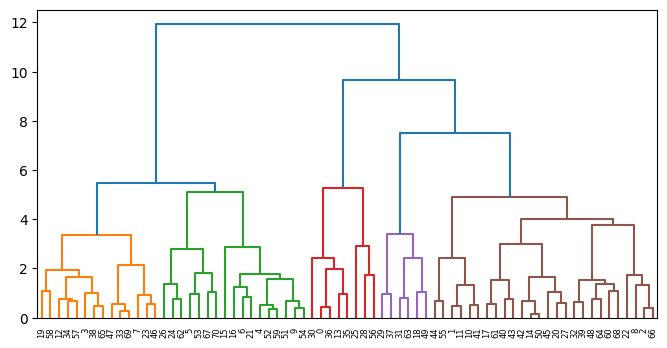

In [14]:
Z = linkage(df_scaled, method='ward', metric='euclidean')

plt.figure(figsize=(8, 4))
dendrogram(Z, color_threshold=5.4, orientation="top")

In [13]:
df_with_clusters

,x1,x2,x3,x4,clusters
regions,,,,,
Алтайский край,-0.833573,-0.833573,-0.833573,-0.833573,0
Амурская область,-2.019004,-2.019004,-2.019004,-2.019004,1
Архангельская область,-1.745080,-1.745080,-1.745080,-1.745080,1
Астраханская область,0.493543,0.493543,0.493543,0.493543,4
Белгородская область,1.263364,1.263364,1.263364,1.263364,3
...,...,...,...,...,...
Хабаровский край,-1.456987,-1.456987,-1.456987,-1.456987,1
Челябинская область,0.021259,0.021259,0.021259,0.021259,2
Чеченская Республика,-1.395590,-1.395590,-1.395590,-1.395590,1
